# Correlatos do Sinal Tarifa Zero por zona

O `Sinal_tarifa_zero` de cada zona OD (`03_comparacoes/compara_demanda_oferta_genero_idade.ipynb`,
Seção 3) é a variação % do embarque médio por dia no domingo menos a do dia útil, 2024 contra 2023
(`PctDiff_domingo − PctDiff_util`, em pontos percentuais). Este notebook o coloca contra
características da zona, uma a uma:

| variável | origem |
|---|---|
| renda domiciliar per capita média | Censo 2022, amostra — `01/06_cria_base_renda_zona.ipynb` |
| % de pessoas negras (pretas + pardas) | Censo 2022, Universo — `01/08_cria_base_covariaveis_zona.ipynb` |
| partidas por domingo (2023) | linhas cujo traçado cruza a zona — notebook principal, Seção 4 |
| lugares ofertados por domingo (2023) | partidas × capacidade média do veículo, idem |
| distância pela rede viária à estação | r5py — `01/09_cria_base_dist_rede_estacao.ipynb` |

**Universo.** Zonas do município de São Paulo com demanda e acima do **percentil 5 do dia médio de
2023** (a base mínima definida na Seção 3 do notebook principal). Cada ponto é uma zona, **sem
ponderar por população**.

**Como ler.** São associações entre zonas, não efeito causal: renda, raça, oferta e distância ao trilho
andam juntas no território (a correlação entre as variáveis está na Seção 2) e as zonas vizinhas se parecem (Moran's I), e a oferta de uma zona
cresce com o seu tamanho — uma partida conta em todas as zonas que a linha cruza. Só ficam em
`outputs/04/`, nada daqui vai para `docs/`.

**Onde o sinal se aglomera.** A Seção 3 traz o Moran local (LISA): quais zonas formam aglomerados de
sinal alto ou baixo, e quais destoam das vizinhas.

## Seção 0 — imports e configuração

In [1]:
from pathlib import Path

import esda
import folium
import geopandas as gpd
import libpysal
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from matplotlib.colors import to_hex
from matplotlib.patches import Patch
from matplotlib.ticker import FuncFormatter

COD_MUNI_SP = 36
DIST_VIZINHANCA_M = 1000   # Moran's I: sao vizinhas as zonas a ate esta distancia, borda a borda (0 = se tocam)
PERM_LISA = 9999           # permutacoes condicionais do Moran local
ALFA_LISA = 0.05           # corte do pseudo-p local, sem correcao para testes multiplos (leitura exploratoria)
SHP_ZONAS = Path("../Dados/pacote-anexos-od_10-02-25_0/002_Site Metro Mapas/Shape/Zonas_2023.shp")

DIR_01 = Path("../outputs/01")
DIR_03 = Path("../outputs/03")
DIR_OUT = Path("../outputs/04")
DIR_FIG = DIR_OUT / "figuras"
DIR_TAB = DIR_OUT / "tabelas"
for d in (DIR_FIG, DIR_TAB):
    d.mkdir(parents=True, exist_ok=True)
SALVAR_FIG = dict(dpi=150, bbox_inches="tight", facecolor="white")

# Fundo dos mapas folium: Esri Light Gray (o preset "CartoDB positron" devolve um tile "API KEY REQUIRED").
TILES_FUNDO = "https://server.arcgisonline.com/ArcGIS/rest/services/Canvas/World_Light_Gray_Base/MapServer/tile/{z}/{y}/{x}"
TILES_FUNDO_ATTR = "Tiles &copy; Esri &mdash; Esri, HERE, Garmin, &copy; OpenStreetMap contributors"

# Tinta e marcas. Texto sempre em cinza-escuro; a cor identifica a marca, nao o texto.
COR_PONTO, COR_MEDIANA, COR_TEXTO, COR_GRADE, COR_SEM_DADO = "#3b6ea5", "#b5481e", "#262626", "#e3e3e3", "#d9d9d9"
Y = "Sinal_tarifa_zero"
Y_ROTULO = "Sinal Tarifa Zero (p.p.)"

# Clusters do Moran local: um matiz para o sinal alto (vermelho) e outro para o baixo (azul); tom forte
# quando as vizinhas acompanham a zona, claro quando a zona destoa delas; cinza neutro sem significancia.
NS_LISA, FORA_LISA = "Não significativo", "Fora da análise"
CORES_LISA = {"Alto-alto": "#d8403f", "Baixo-baixo": "#256abf", "Alto-baixo": "#ec8a89", "Baixo-alto": "#6da7ec", NS_LISA: "#f0efec"}
LEGENDA_LISA = {
    "Alto-alto": "Alto-alto: zona e vizinhas com sinal alto",
    "Baixo-baixo": "Baixo-baixo: zona e vizinhas com sinal baixo",
    "Alto-baixo": "Alto-baixo: zona alta entre vizinhas baixas",
    "Baixo-alto": "Baixo-alto: zona baixa entre vizinhas altas",
    NS_LISA: NS_LISA,
}


def fmt_br(x, casas=2):
    # 1234.5 -> "1.234,50"
    return f"{x:,.{casas}f}".replace(",", "X").replace(".", ",").replace("X", ".")


def fmt_eixo(x, _=None):
    return fmt_br(x, 0) if x >= 1000 else f"{x:g}".replace(".", ",")

## Seção 1 — base por zona

Junta, por `NumeroZona`, o sinal, a renda, as covariáveis do Censo e das estações, e a oferta de
domingo/2023. A distância de rede entra se o notebook `09` já tiver rodado.

In [2]:
zonas = gpd.read_file(SHP_ZONAS)[["NumeroZona", "NomeZona", "NumeroMuni", "geometry"]]
zonas = zonas[zonas["NumeroMuni"] == COD_MUNI_SP].drop(columns="NumeroMuni").reset_index(drop=True)

sinal = pd.read_parquet(DIR_03 / "sinal_zona.parquet")
renda = pd.read_parquet(DIR_01 / "renda_zona_censo2022.parquet")[["NumeroZona", "pop", "renda_pc_media", "quintil_renda"]]
cov = pd.read_parquet(DIR_01 / "covariaveis_zona.parquet")[["NumeroZona", "pct_negros"]]
oferta = pd.read_parquet(DIR_03 / "oferta_zona.parquet")
oferta_dom = (
    oferta[(oferta["Ano"] == "2023") & (oferta["tipo_dia"] == "domingo")]
    .rename(columns={"partidas_dia": "partidas_dom_2023", "lugares_dia": "lugares_dom_2023"})
    [["NumeroZona", "partidas_dom_2023", "lugares_dom_2023"]]
)

base_zona = (
    zonas[["NumeroZona", "NomeZona"]]
    .merge(sinal, on="NumeroZona", how="left")
    .merge(renda, on="NumeroZona", how="left")
    .merge(cov, on="NumeroZona", how="left")
    .merge(oferta_dom, on="NumeroZona", how="left")
)
ARQ_REDE = DIR_01 / "dist_rede_estacao_zona.parquet"
if ARQ_REDE.exists():
    base_zona = base_zona.merge(
        pd.read_parquet(ARQ_REDE)[["NumeroZona", "dist_estacao_rede_km"]], on="NumeroZona", how="left")
else:
    print("dist_rede_estacao_zona.parquet ainda nao existe: rode o notebook 09 e reexecute este.")

analise = base_zona[base_zona[Y].notna()].copy()    # fora: base pequena (p05) e zonas sem demanda
print(f"zonas de SP: {len(base_zona)} | com demanda: {base_zona['dia_medio_2023'].notna().sum()} | "
      f"base pequena (abaixo do p05): {int(base_zona['base_pequena'].fillna(False).sum())} | na analise: {len(analise)}")
assert analise["renda_pc_media"].notna().all() and analise["partidas_dom_2023"].notna().all()

analise.to_parquet(DIR_OUT / "base_zona_correlatos.parquet", index=False)
analise.describe().T[["count", "mean", "min", "50%", "max"]].round(2)

zonas de SP: 343 | com demanda: 339 | base pequena (abaixo do p05): 17 | na analise: 322


,count,mean,min,50%,max
NumeroZona,322.0,174.78,1.00,178.00,343.00
dia_domingo_2023,322.0,6733.11,193.07,4439.34,49146.83
dia_sabado_2023,322.0,12837.58,943.95,8761.74,84312.82
dia_util_2023,322.0,21208.94,2472.05,14570.76,126638.75
dia_domingo_2024,322.0,8649.43,286.31,5930.07,56708.90
dia_sabado_2024,322.0,12176.45,806.88,8373.36,78991.42
dia_util_2024,322.0,22063.74,2279.11,14655.35,128627.02
PctDiff_domingo,322.0,33.19,-22.70,32.21,88.14
PctDiff_util,322.0,3.39,-34.60,3.11,37.17
Sinal_tarifa_zero,322.0,29.80,1.95,28.93,75.27


## Seção 2 — gráficos XY: reta de MQO, inclinação e Moran's I

Cada painel mostra as zonas (pontos) e a **reta de mínimos quadrados** do sinal sobre a variável, com a
faixa de confiança de 95% da reta. Nas variáveis muito assimétricas (renda, partidas, lugares) a
regressão é feita no **log2** — a inclinação é "p.p. de sinal por dobra da variável" e a reta aparece
reta no eixo logarítmico; em % de negros (por +10 p.p.) e distância pela rede (por +1 km) a escala é
linear. Intervalos pelo erro-padrão robusto **HC3** (heterocedasticidade).

**Autocorrelação espacial.** Zonas vizinhas se parecem, então os intervalos acima assumem mais zonas
independentes do que existem e **estão otimistas**. Cada painel traz o **Moran's I do resíduo** da
regressão (vizinhas = zonas a até 1 km uma da outra, medido de borda a borda, o que inclui as que se
tocam; linhas padronizadas, 999 permutações): valor alto e significativo
= o resíduo ainda tem estrutura espacial que a variável não explica. O Moran's I do próprio sinal vem
abaixo. Modelo espacial (`spreg`) é o passo seguinte para inferência.

vizinhas por zona, ate 1000 m: min 1, mediana 10, media 10.0, max 22 | so as que se tocam: min 1, mediana 6, media 5.6, max 9
Moran's I do sinal: 0.453 (p pseudo = 0.001, vizinhas ate 1000 m, 999 permutacoes, n = 322)



Sinal Tarifa Zero ~ variavel (MQO simples, IC HC3):
                        n       unidade  inclinacao_pp  ic95_baixo  ic95_alto     r2  moran_residuo  moran_residuo_p
variavel                                                                                                            
renda_pc_media        322     por dobra         -1.141      -2.457      0.174  0.009          0.461            0.001
pct_negros            322  por +10 p.p.          0.300      -0.525      1.125  0.002          0.456            0.001
partidas_dom_2023     322     por dobra         -3.096      -4.683     -1.509  0.039          0.456            0.001
lugares_dom_2023      322     por dobra         -1.968      -3.517     -0.420  0.018          0.462            0.001
dist_estacao_rede_km  322     por +1 km         -1.014      -1.729     -0.299  0.020          0.428            0.001


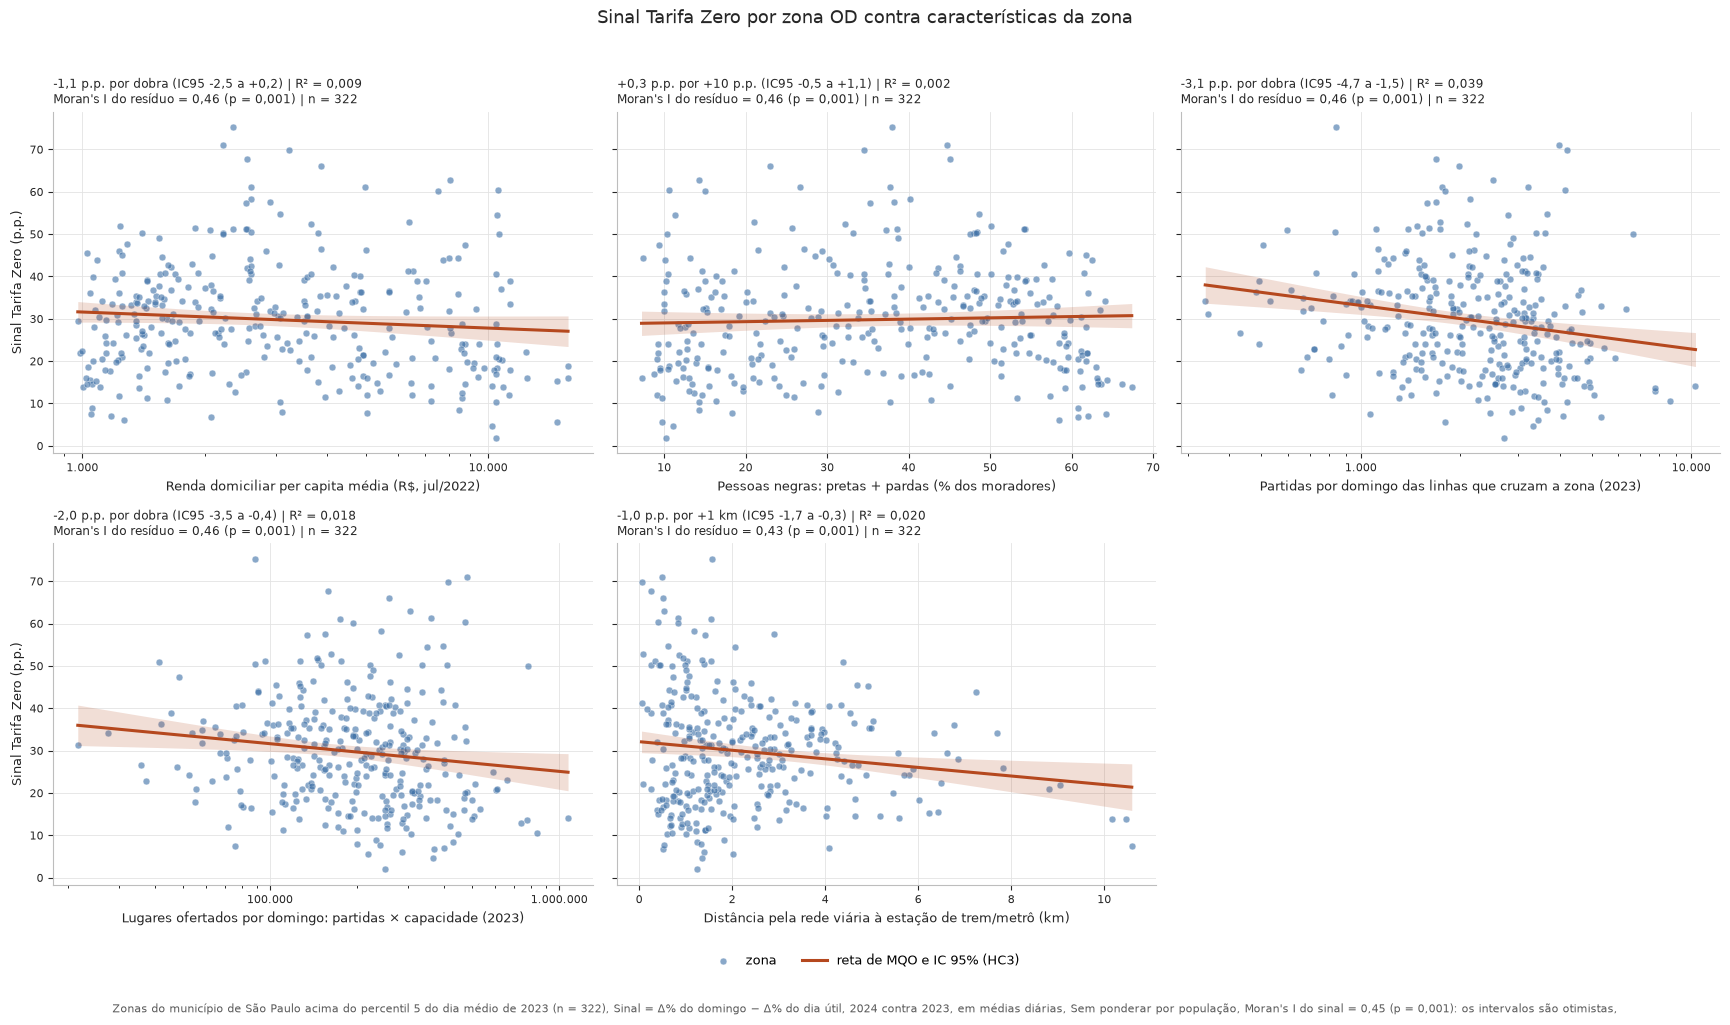


Correlacao de Pearson entre as variaveis (na escala do ajuste) e o sinal:
                      renda_pc_media  pct_negros  partidas_dom_2023  lugares_dom_2023  dist_estacao_rede_km  Sinal_tarifa_zero
renda_pc_media                  1.00       -0.91               0.03              0.18                 -0.52              -0.09
pct_negros                     -0.91        1.00              -0.01             -0.14                  0.52               0.04
partidas_dom_2023               0.03       -0.01               1.00              0.96                 -0.16              -0.20
lugares_dom_2023                0.18       -0.14               0.96              1.00                 -0.27              -0.14
dist_estacao_rede_km           -0.52        0.52              -0.16             -0.27                  1.00              -0.14
Sinal_tarifa_zero              -0.09        0.04              -0.20             -0.14                 -0.14               1.00


In [3]:
VARIAVEIS = [
    dict(col="renda_pc_media", rotulo="Renda domiciliar per capita média (R$, jul/2022)", curto="Renda per capita (R$)", log=True, unid="por dobra"),
    dict(col="pct_negros", rotulo="Pessoas negras: pretas + pardas (% dos moradores)", curto="% de pessoas negras", log=False, esc=10, unid="por +10 p.p."),
    dict(col="partidas_dom_2023", rotulo="Partidas por domingo das linhas que cruzam a zona (2023)", curto="Partidas por domingo", log=True, unid="por dobra"),
    dict(col="lugares_dom_2023", rotulo="Lugares ofertados por domingo: partidas × capacidade (2023)", curto="Lugares por domingo", log=True, unid="por dobra"),
    dict(col="dist_estacao_rede_km", rotulo="Distância pela rede viária à estação de trem/metrô (km)", curto="Dist. de rede à estação (km)", log=False, esc=1, unid="por +1 km"),
]
VARIAVEIS = [v for v in VARIAVEIS if v["col"] in analise.columns]


def x_ajuste(x, v):
    # a escala em que a reta e ajustada: log2 (inclinacao por dobra) ou linear / esc
    return np.log2(x) if v["log"] else x / v["esc"]


def mqo(x, y):
    # MQO simples com erro-padrao robusto HC3; devolve coeficientes, covariancia, residuos e R2
    X = np.column_stack([np.ones(len(x)), x])
    xtx = np.linalg.inv(X.T @ X)
    b = xtx @ X.T @ y
    e = y - X @ b
    h = np.einsum("ij,jk,ik->i", X, xtx, X)
    cov = xtx @ (X.T * (e / (1 - h)) ** 2) @ X @ xtx
    return b, cov, e, 1 - e.var() / y.var()


# Pesos de vizinhanca entre as zonas da analise: poligonos a ate DIST_VIZINHANCA_M um do outro, borda a
# borda. Quem se toca esta a distancia 0, entao a contiguidade tipo rainha esta contida no criterio.
assert zonas.crs.is_projected, "a distancia entre zonas precisa de CRS projetado (metros)"
zon_a = zonas[zonas["NumeroZona"].isin(analise["NumeroZona"])].set_index("NumeroZona").loc[analise["NumeroZona"]].reset_index()
viz = gpd.sjoin(zon_a[["geometry"]], zon_a[["geometry"]], predicate="dwithin", distance=DIST_VIZINHANCA_M)
viz = viz[viz.index != viz["index_right"]]
W = np.zeros((len(zon_a), len(zon_a)))
W[viz.index.values, viz["index_right"].values] = 1
assert (W.sum(1) > 0).all(), "zona sem vizinha"
toca = gpd.sjoin(zon_a[["geometry"]], zon_a[["geometry"]], predicate="intersects")
n_toca = np.bincount(toca.index[toca.index != toca["index_right"]], minlength=len(zon_a))
n_viz = W.sum(1)
print(f"vizinhas por zona, ate {DIST_VIZINHANCA_M} m: min {int(n_viz.min())}, mediana {np.median(n_viz):.0f}, "
      f"media {n_viz.mean():.1f}, max {int(n_viz.max())} | so as que se tocam: min {n_toca.min()}, "
      f"mediana {np.median(n_toca):.0f}, media {n_toca.mean():.1f}, max {n_toca.max()}")
W = W / W.sum(1, keepdims=True)


def moran(v, perm=999, seed=1):
    z = v - v.mean()
    I = (z @ W @ z) / (z @ z)
    rng = np.random.default_rng(seed)
    sim = np.array([(p := rng.permutation(z)) @ W @ p / (z @ z) for _ in range(perm)])
    return I, (1 + (sim >= I).sum()) / (perm + 1)


I_sinal, p_sinal = moran(analise[Y].to_numpy())
print(f"Moran's I do sinal: {I_sinal:.3f} (p pseudo = {p_sinal:.3f}, vizinhas ate {DIST_VIZINHANCA_M} m, 999 permutacoes, n = {len(analise)})")

linhas_reg = []
for v in VARIAVEIS:
    assert analise[v["col"]].notna().all(), f"{v['col']} tem zonas sem valor: o Moran do residuo precisa de todas"
    x = x_ajuste(analise[v["col"]].to_numpy(), v)
    y = analise[Y].to_numpy()
    b, cov, e, r2 = mqo(x, y)
    se = np.sqrt(cov[1, 1])
    I_r, p_r = moran(e)
    v.update(b=b, cov=cov)
    linhas_reg.append(dict(variavel=v["col"], rotulo=v["curto"], n=len(y), unidade=v["unid"], inclinacao_pp=b[1],
                           ic95_baixo=b[1] - 1.96 * se, ic95_alto=b[1] + 1.96 * se, r2=r2, moran_residuo=I_r, moran_residuo_p=p_r))
regressoes = pd.DataFrame(linhas_reg).set_index("variavel")
regressoes.to_parquet(DIR_TAB / "regressoes_sinal_zona.parquet")
pd.DataFrame([dict(variavel=Y, moran_i=I_sinal, p_pseudo=p_sinal, n=len(analise))]).to_parquet(DIR_TAB / "moran_sinal_zona.parquet", index=False)
print("\nSinal Tarifa Zero ~ variavel (MQO simples, IC HC3):")
print(regressoes.drop(columns="rotulo").round(3).to_string())


def painel_xy(ax, v, rotulo_y=True):
    d = analise[[v["col"], Y]]
    ax.scatter(d[v["col"]], d[Y], s=24, color=COR_PONTO, alpha=.6, edgecolor="white", linewidth=.4, zorder=2, label="zona")
    xs = np.geomspace(d[v["col"]].min(), d[v["col"]].max(), 200) if v["log"] else np.linspace(d[v["col"]].min(), d[v["col"]].max(), 200)
    X = np.column_stack([np.ones(len(xs)), x_ajuste(xs, v)])
    ajuste = X @ v["b"]
    ep = np.sqrt(np.einsum("ij,jk,ik->i", X, v["cov"], X))
    ax.fill_between(xs, ajuste - 1.96 * ep, ajuste + 1.96 * ep, color=COR_MEDIANA, alpha=.18, lw=0, zorder=3)
    ax.plot(xs, ajuste, color=COR_MEDIANA, lw=2.2, zorder=4, label="reta de MQO e IC 95% (HC3)")
    if v["log"]:
        ax.set_xscale("log")
    ax.xaxis.set_major_formatter(FuncFormatter(fmt_eixo))
    reg = regressoes.loc[v["col"]]
    ax.set_title((f"{reg['inclinacao_pp']:+.1f} p.p. {v['unid']} (IC95 {reg['ic95_baixo']:+.1f} a {reg['ic95_alto']:+.1f}) | R² = {reg['r2']:.3f}\n"
                  f"Moran's I do resíduo = {reg['moran_residuo']:.2f} (p = {reg['moran_residuo_p']:.3f}) | n = {int(reg['n'])}").replace("p.p.", "§").replace(".", ",").replace("§", "p.p."),
                 loc="left", fontsize=8.5, color=COR_TEXTO)
    ax.set_xlabel(v["rotulo"], fontsize=9, color=COR_TEXTO)
    if rotulo_y:
        ax.set_ylabel(Y_ROTULO, fontsize=9, color=COR_TEXTO)
    ax.grid(color=COR_GRADE, lw=.6)
    ax.set_axisbelow(True)
    for lado in ("top", "right"):
        ax.spines[lado].set_visible(False)
    for lado in ("left", "bottom"):
        ax.spines[lado].set_color("#bdbdbd")
    ax.tick_params(colors=COR_TEXTO, labelsize=8)


n = len(VARIAVEIS)
colunas = 3
linhas = int(np.ceil(n / colunas))
fig, axes = plt.subplots(linhas, colunas, figsize=(5.8 * colunas, 4.8 * linhas), sharey=True, squeeze=False)
for i, (ax, v) in enumerate(zip(axes.ravel(), VARIAVEIS)):
    painel_xy(ax, v, rotulo_y=(i % colunas == 0))
for ax in axes.ravel()[n:]:
    ax.set_axis_off()
h, l = axes[0, 0].get_legend_handles_labels()
fig.legend(h, l, loc="lower center", ncol=2, frameon=False, fontsize=9, bbox_to_anchor=(.5, -.01))
fig.suptitle("Sinal Tarifa Zero por zona OD contra características da zona", fontsize=13, color=COR_TEXTO, y=1.0)
fig.text(.5, -.045, (f"Zonas do município de São Paulo acima do percentil 5 do dia médio de 2023 (n = {len(analise)}). Sinal = Δ% do domingo − Δ% do dia útil, 2024 contra 2023, "
         f"em médias diárias. Sem ponderar por população. Moran's I do sinal = {I_sinal:.2f} (p = {p_sinal:.3f}): os intervalos são otimistas.").replace(", Sem", ". Sem").replace("p.p.", "§").replace(".", ",").replace("§", "p.p."),
         ha="center", fontsize=8, color="#595959")
fig.tight_layout(rect=(0, .03, 1, .98))
fig.savefig(DIR_FIG / "xy_sinal_variaveis.png", **SALVAR_FIG)
plt.show()

# um arquivo por variavel, para uso isolado
for v in VARIAVEIS:
    f1, a1 = plt.subplots(figsize=(7.5, 5.2))
    painel_xy(a1, v)
    a1.legend(frameon=False, fontsize=8, loc="lower right")
    f1.savefig(DIR_FIG / f"xy_{v['col']}.png", **SALVAR_FIG)
    plt.close(f1)

# As variaveis andam juntas no territorio: Pearson entre elas, na escala do ajuste.
escala_ajuste = pd.DataFrame({v["col"]: x_ajuste(analise[v["col"]], v) for v in VARIAVEIS})
escala_ajuste[Y] = analise[Y].to_numpy()
entre_si = escala_ajuste.corr()
entre_si.to_parquet(DIR_TAB / "correlacao_entre_variaveis.parquet")
print("\nCorrelacao de Pearson entre as variaveis (na escala do ajuste) e o sinal:")
print(entre_si.round(2).to_string())

## Seção 3 — Moran local (LISA): onde o sinal se aglomera

O Moran's I global diz que as zonas vizinhas se parecem, mas não onde. O **Moran local** (LISA) dá um I
para cada zona (o desvio do sinal da zona em relação à média, vezes o desvio da média das suas
vizinhas) e a classifica em um de quatro tipos:

| tipo | a zona | as vizinhas |
|---|---|---|
| alto-alto | sinal acima da média | acima da média |
| baixo-baixo | abaixo da média | abaixo da média |
| alto-baixo | acima da média | abaixo da média |
| baixo-alto | abaixo da média | acima da média |

"Alto" e "baixo" são relativos à **média do sinal entre as zonas** (cerca de 30 p.p.), não a zero: o
sinal é positivo em todas as zonas da análise. Um aglomerado baixo-baixo é onde o domingo cresceu
menos em relação ao dia útil, não onde caiu.

**Vizinhança.** A mesma da Seção 2 (zonas a até 1 km, linhas padronizadas), com `esda.Moran_Local`.

**Significância.** 9.999 permutações condicionais: o valor da zona fica fixo e as vizinhas são
sorteadas entre as outras zonas. O pseudo-p é unicaudal na direção observada, a convenção do GeoDa, e
o corte é **p < 0,05, sem correção para testes múltiplos**: é uma leitura exploratória, antes do modelo
espacial. São 322 testes de uma vez, então cerca de 16 zonas podem estar marcadas por acaso. Vale ler
os blocos grandes e contíguos, não as zonas isoladas. O pseudo-p de cada zona vai na tabela (`p_sim`),
para quem quiser aplicar outro corte.

**Cuidados.** Em zona com poucas vizinhas a média das vizinhas é instável (`n_vizinhas` vai na
tabela). O sinal é a diferença de duas variações percentuais e fica ruidoso em zona de base pequena:
uma zona alto-baixo ou baixo-alto isolada pode ser ruído. As zonas fora da análise (sem demanda ou
abaixo do corte de base mínima) não são vizinhas de ninguém.

In [4]:
y = analise[Y].to_numpy()
w = libpysal.weights.full2W(W)      # a mesma vizinhanca da Secao 2
w.transform = "r"

# o esda tem de reproduzir o I global calculado a mao na Secao 2
I_esda = esda.Moran(y, w, permutations=0).I
assert abs(I_esda - I_sinal) < 1e-9, f"I global: esda {I_esda:.6f} x Secao 2 {I_sinal:.6f}"

# Permutacao condicional: o valor da zona fica fixo e as vizinhas sao sorteadas entre as outras zonas.
# "directed" = pseudo-p unicaudal na direcao observada (convencao do GeoDa).
lisa = esda.Moran_Local(y, w, transformation="r", permutations=PERM_LISA, seed=1, alternative="directed")

QUADRANTES = {1: "Alto-alto", 2: "Baixo-alto", 3: "Baixo-baixo", 4: "Alto-baixo"}   # numeracao do PySAL
lisa_zona = pd.DataFrame({
    "NumeroZona": analise["NumeroZona"].to_numpy(),
    "NomeZona": analise["NomeZona"].to_numpy(),
    Y: y,
    "media_vizinhas": W @ y,
    "n_vizinhas": n_viz.astype(int),
    "lisa_i": lisa.Is,
    "quadrante": pd.Series(lisa.q).map(QUADRANTES).to_numpy(),
    "p_sim": lisa.p_sim,
})
# corte unico, sem correcao para testes multiplos; o p_sim fica na tabela para outros cortes
lisa_zona["cluster"] = lisa_zona["quadrante"].where(lisa_zona["p_sim"] < ALFA_LISA, NS_LISA)
n_sig = int((lisa_zona["cluster"] != NS_LISA).sum())

resumo_lisa = lisa_zona.groupby("cluster")[Y].agg(n="size", sinal_medio="mean").reindex(list(CORES_LISA))
resumo_lisa["n"] = resumo_lisa["n"].fillna(0).astype(int)
assert resumo_lisa["n"].sum() == len(analise)

lisa_zona.to_parquet(DIR_TAB / "lisa_sinal_zona.parquet", index=False)
resumo_lisa.to_parquet(DIR_TAB / "lisa_resumo.parquet")

print(f"Moran local do sinal: {PERM_LISA} permutacoes condicionais, n = {len(y)}, media do sinal = {y.mean():.1f} p.p.")
print(f"zonas com p < {ALFA_LISA} (sem correcao para testes multiplos): {n_sig}\n")
print(resumo_lisa.round(1).to_string())
for nome in list(CORES_LISA)[:4]:
    d = lisa_zona[lisa_zona["cluster"] == nome].sort_values(Y, ascending=False)
    print(f"\n{nome}, {len(d)} zonas (sinal em p.p.): " + ", ".join(f"{z} ({s:.0f})" for z, s in zip(d["NomeZona"], d[Y])))
poucas = lisa_zona[(lisa_zona["cluster"] != NS_LISA) & (lisa_zona["n_vizinhas"] <= 2)]
print(f"\nzonas significativas com ate 2 vizinhas: {len(poucas)}")

Moran local do sinal: 9999 permutacoes condicionais, n = 322, media do sinal = 29.8 p.p.
zonas com p < 0.05 (sem correcao para testes multiplos): 141

                     n  sinal_medio
cluster                            
Alto-alto           60         47.3
Baixo-baixo         68         17.1
Alto-baixo           5         34.3
Baixo-alto           8         20.9
Não significativo  181         29.0

Alto-alto, 60 zonas (sinal em p.p.): Pari (75), Praça João Mendes (71), República (70), Ponte Pequena (68), Liberdade (66), Ana Rosa (63), Brás (61), Trianon (60), França Pinto (60), Oriente (58), Vila Guilherme (58), Belém (57), Santa Ifigênia (55), Vila Buarque (53), Bexiga (52), Vila Cardoso Franco (52), Linhas Corrente (51), Canindé (51), Celso Garcia (51), Luz (51), João Teodoro (50), Sé (50), Parque Santa Madalena (50), Santa Cecília (50), Parque Dom Pedro (50), Jardim Colorado (49), Teotônio Vilela (48), Higienópolis (47), Glicério (46), Vila Monumento (46), Fazenda da Juta (46), Vi

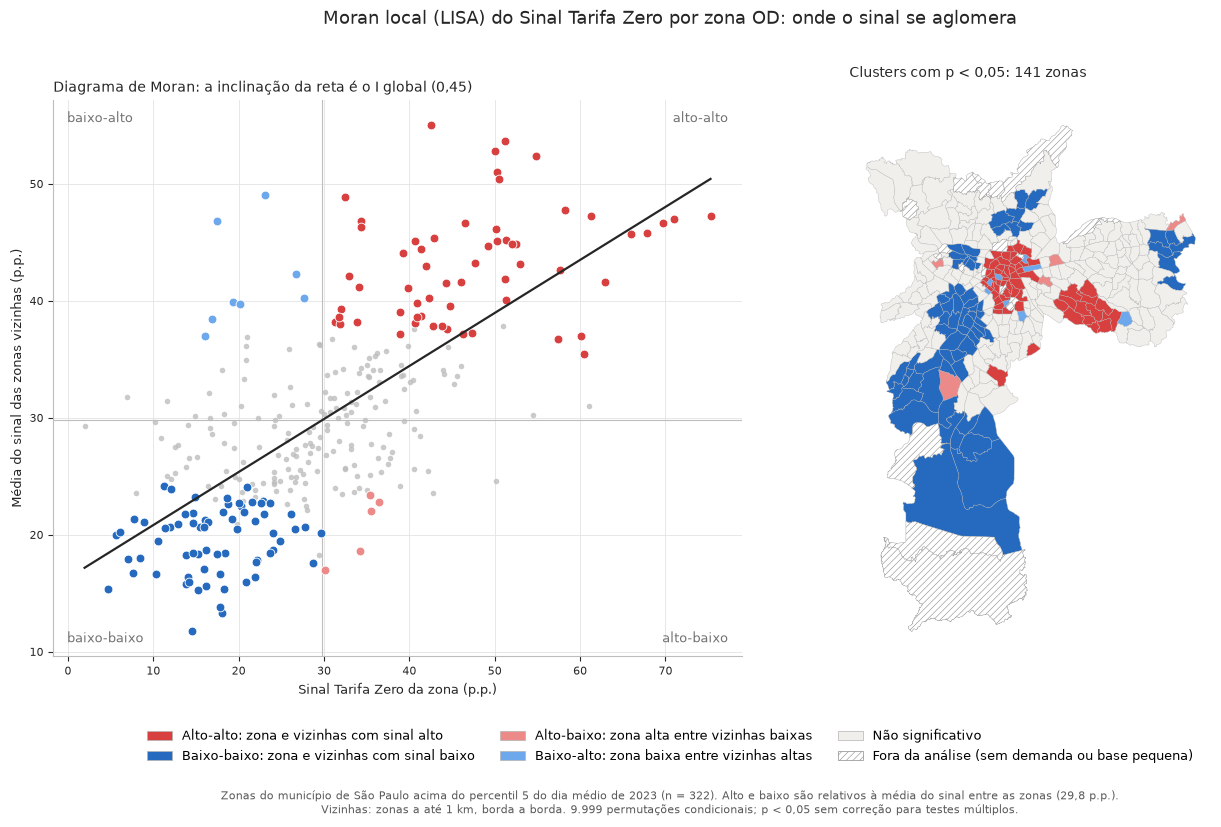

In [5]:
zonas_lisa = zonas[["NumeroZona", "geometry"]].merge(lisa_zona[["NumeroZona", "cluster"]], on="NumeroZona", how="left")
media = y.mean()
COR_BORDA, COR_FORA = "#b3b3b3", "#8c8c8c"

with plt.rc_context({"hatch.linewidth": .4}):
    fig, (ax0, ax1) = plt.subplots(1, 2, figsize=(13.5, 7.8), gridspec_kw=dict(width_ratios=[1.15, 1]))

    # Diagrama de Moran: sinal da zona x media das vizinhas. Os eixos cruzam na media do sinal e a
    # inclinacao da reta e o I global. As zonas significativas sao maiores e levam a cor do cluster.
    ax0.axvline(media, color="#bdbdbd", lw=.8, zorder=1)
    ax0.axhline(media, color="#bdbdbd", lw=.8, zorder=1)
    ns = lisa_zona["cluster"] == NS_LISA
    ax0.scatter(lisa_zona.loc[ns, Y], lisa_zona.loc[ns, "media_vizinhas"], s=16, color="#bdbdbd", alpha=.8, linewidth=0, zorder=2)
    for nome in list(CORES_LISA)[:4]:
        d = lisa_zona[lisa_zona["cluster"] == nome]
        ax0.scatter(d[Y], d["media_vizinhas"], s=40, color=CORES_LISA[nome], edgecolor="white", linewidth=.6, zorder=3)
    xs = np.array([y.min(), y.max()])
    ax0.plot(xs, media + I_sinal * (xs - media), color=COR_TEXTO, lw=1.6, zorder=4)
    for txt, (px, py, ha, va) in {"alto-alto": (.98, .98, "right", "top"), "baixo-alto": (.02, .98, "left", "top"),
                                  "baixo-baixo": (.02, .02, "left", "bottom"), "alto-baixo": (.98, .02, "right", "bottom")}.items():
        ax0.text(px, py, txt, transform=ax0.transAxes, ha=ha, va=va, fontsize=9, color="#737373")
    ax0.set_title(f"Diagrama de Moran: a inclinação da reta é o I global ({fmt_br(I_sinal)})", loc="left", fontsize=10, color=COR_TEXTO)
    ax0.set_xlabel("Sinal Tarifa Zero da zona (p.p.)", fontsize=9, color=COR_TEXTO)
    ax0.set_ylabel("Média do sinal das zonas vizinhas (p.p.)", fontsize=9, color=COR_TEXTO)
    ax0.grid(color=COR_GRADE, lw=.6)
    ax0.set_axisbelow(True)
    for lado in ("top", "right"):
        ax0.spines[lado].set_visible(False)
    for lado in ("left", "bottom"):
        ax0.spines[lado].set_color("#bdbdbd")
    ax0.tick_params(colors=COR_TEXTO, labelsize=8)

    # Mapa: zonas da analise na cor do cluster; as de fora, hachuradas (sem cor, para nao se confundir
    # com "nao significativo")
    dentro = zonas_lisa[zonas_lisa["cluster"].notna()]
    dentro.plot(color=dentro["cluster"].map(CORES_LISA), edgecolor=COR_BORDA, linewidth=.25, ax=ax1)
    zonas_lisa[zonas_lisa["cluster"].isna()].plot(facecolor="white", edgecolor=COR_FORA, linewidth=.25, hatch="/////", ax=ax1)
    ax1.set_title(f"Clusters com p < 0,05: {n_sig} zonas", loc="left", fontsize=10, color=COR_TEXTO)
    ax1.set_axis_off()

    chaves = [Patch(fc=c, ec=COR_BORDA, lw=.5, label=LEGENDA_LISA[k]) for k, c in CORES_LISA.items()]
    chaves.append(Patch(fc="white", ec=COR_FORA, lw=.5, hatch="/////", label=f"{FORA_LISA} (sem demanda ou base pequena)"))
    fig.legend(handles=chaves, loc="lower center", ncol=3, frameon=False, fontsize=9, bbox_to_anchor=(.5, .0))
    fig.suptitle("Moran local (LISA) do Sinal Tarifa Zero por zona OD: onde o sinal se aglomera", fontsize=13, color=COR_TEXTO)
    fig.text(.5, -.05, f"Zonas do município de São Paulo acima do percentil 5 do dia médio de 2023 (n = {len(y)}). Alto e baixo são relativos à média do sinal "
             f"entre as zonas ({fmt_br(media, 1)} p.p.).\nVizinhas: zonas a até {DIST_VIZINHANCA_M / 1000:g} km, borda a borda. {fmt_br(PERM_LISA, 0)} permutações condicionais; "
             f"p < 0,05 sem correção para testes múltiplos.", ha="center", fontsize=8, color="#595959")
    fig.tight_layout(rect=(0, .08, 1, .97))
    fig.savefig(DIR_FIG / "lisa_sinal_zona.png", **SALVAR_FIG)
    plt.show()

## Seção 4 — mapas das variáveis

Um mapa por variável, mais o do sinal, todos em **5 classes com o mesmo número de zonas** (quantis).
As variáveis usam um só matiz (azul), claro → escuro; o sinal usa outro (laranja), para não ser
confundido com as covariáveis. Zonas em cinza não têm a variável (sem moradores no Censo, sem demanda
ou abaixo do corte de base mínima, no caso do sinal).

O mapa interativo traz também uma camada com os **clusters do Moran local** (Seção 3), para alternar entre os aglomerados do sinal e as variáveis.

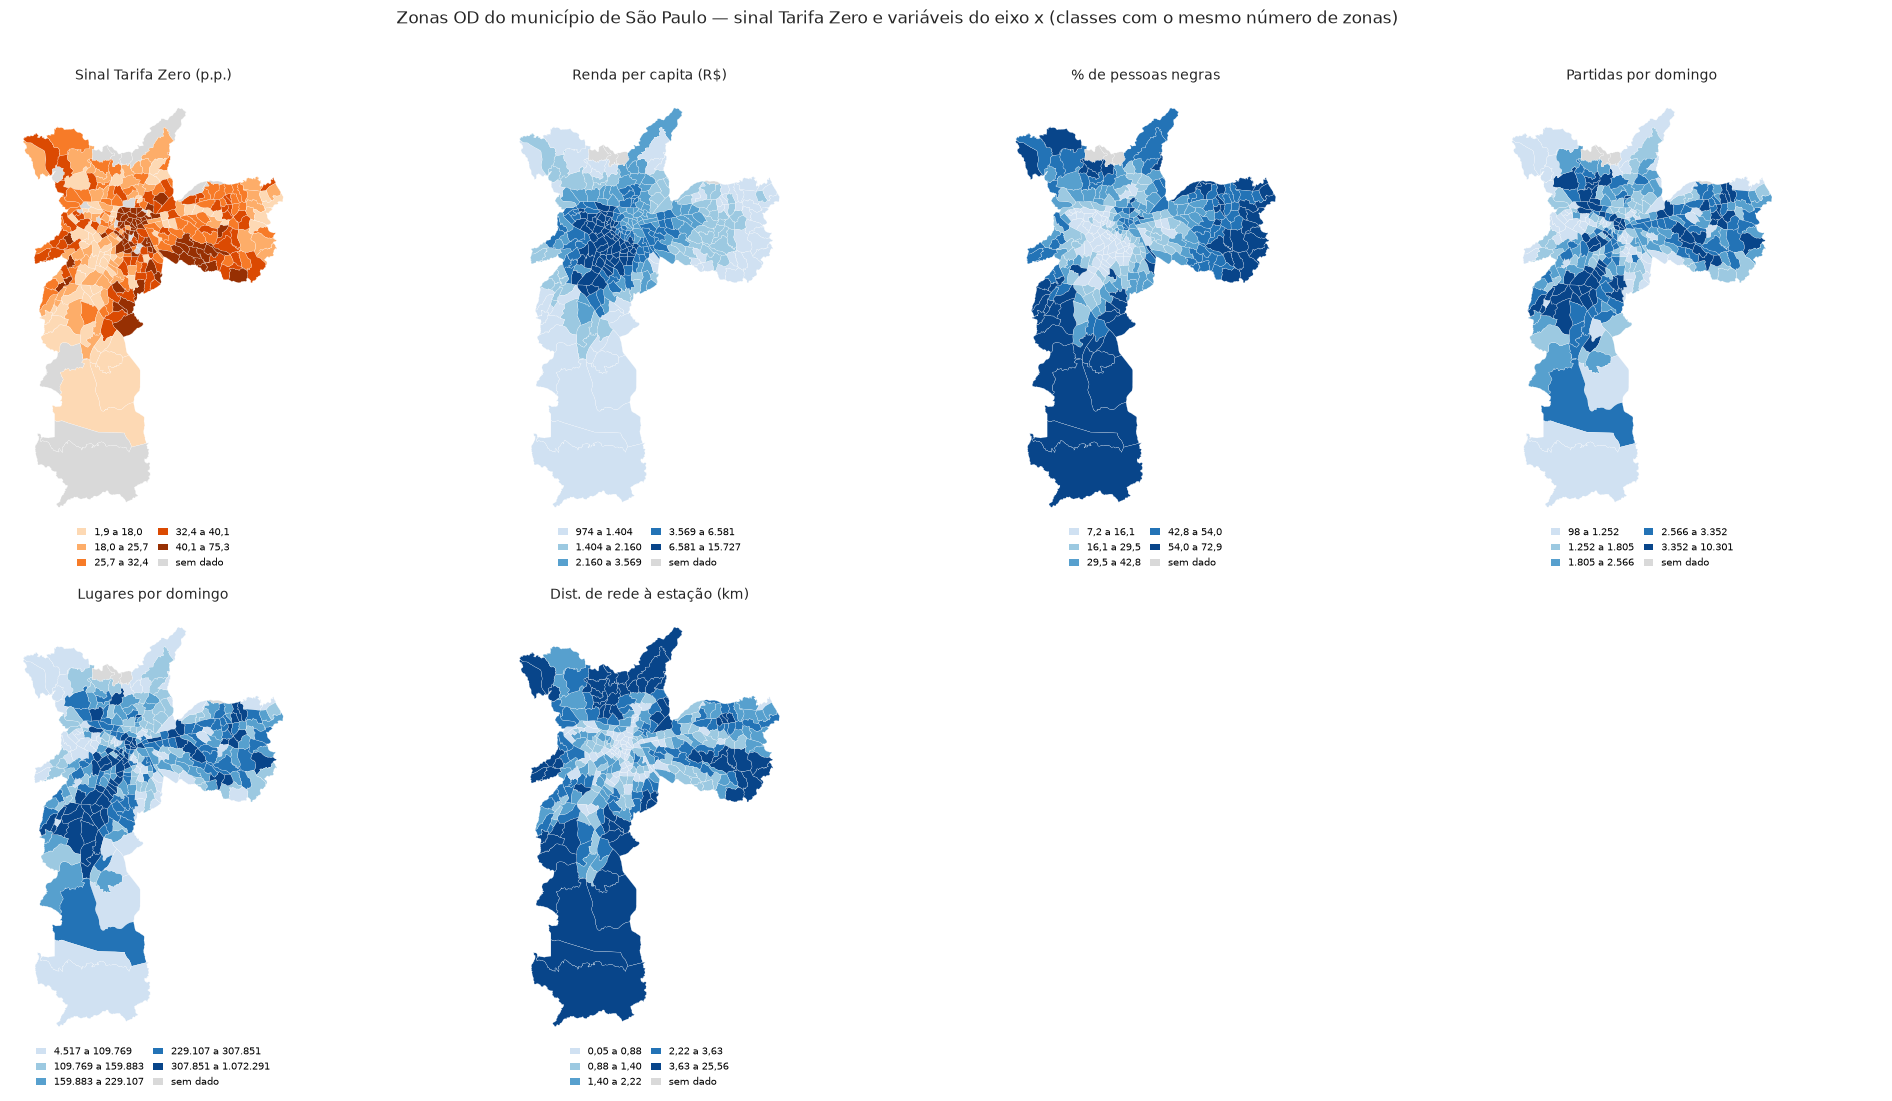

In [6]:
K = 5
RAMPA_VAR = [to_hex(plt.get_cmap("Blues")(t)) for t in np.linspace(.2, .92, K)]
RAMPA_SINAL = [to_hex(plt.get_cmap("Oranges")(t)) for t in np.linspace(.2, .92, K)]

MAPAS = [dict(col=Y, curto="Sinal Tarifa Zero (p.p.)", rampa=RAMPA_SINAL)] + [
    dict(col=v["col"], curto=v["curto"], rampa=RAMPA_VAR) for v in VARIAVEIS]


def classes_quantil(s, k=K):
    cortes = np.unique(s.dropna().quantile(np.linspace(0, 1, k + 1)).to_numpy())
    return pd.cut(s, bins=cortes, include_lowest=True, labels=False), cortes


def rotulos_classes(cortes):
    casas = 0 if cortes[1] >= 100 else (1 if cortes[1] >= 10 else 2)   # pelo 1o corte: distancias curtas pedem 2 casas
    return [f"{fmt_br(a, casas)} a {fmt_br(b, casas)}" for a, b in zip(cortes[:-1], cortes[1:])]


# o sinal so aparece para a analise; as covariaveis, para todas as zonas que as tem
zonas_mapa = zonas.merge(base_zona.drop(columns="NomeZona"), on="NumeroZona", how="left")
zonas_mapa = gpd.GeoDataFrame(zonas_mapa, geometry="geometry", crs=zonas.crs)
legendas = {}
for m in MAPAS:
    cls, cortes = classes_quantil(zonas_mapa[m["col"]])
    zonas_mapa[f"cor_{m['col']}"] = cls.map(lambda c, r=m["rampa"]: r[int(c)] if pd.notna(c) else COR_SEM_DADO)
    legendas[m["col"]] = list(zip(m["rampa"], rotulos_classes(cortes)))

colunas = 4
linhas = int(np.ceil(len(MAPAS) / colunas))
fig, axes = plt.subplots(linhas, colunas, figsize=(5 * colunas, 5.6 * linhas), squeeze=False)
for ax, m in zip(axes.ravel(), MAPAS):
    zonas_mapa.plot(color=zonas_mapa[f"cor_{m['col']}"], edgecolor="white", linewidth=.15, ax=ax)
    ax.set_title(m["curto"], fontsize=10, color=COR_TEXTO)
    ax.set_axis_off()
    ax.legend(handles=[Patch(fc=c, label=r) for c, r in legendas[m["col"]]] + [Patch(fc=COR_SEM_DADO, label="sem dado")],
              loc="upper center", bbox_to_anchor=(.5, .02), ncol=2, frameon=False, fontsize=7, handlelength=1, columnspacing=1)
for ax in axes.ravel()[len(MAPAS):]:
    ax.set_axis_off()
fig.suptitle("Zonas OD do município de São Paulo — sinal Tarifa Zero e variáveis do eixo x (classes com o mesmo número de zonas)",
             fontsize=12, color=COR_TEXTO)
fig.tight_layout(rect=(0, 0, 1, .97))
fig.savefig(DIR_FIG / "mapas_variaveis_zona.png", **SALVAR_FIG)
plt.show()

In [7]:
# Mapa interativo: uma camada por variavel (botao de radio), tooltip unico com todos os valores.
zonas_wgs = zonas_mapa.to_crs(4326).merge(lisa_zona[["NumeroZona", "cluster"]], on="NumeroZona", how="left")
zonas_wgs["geometry"] = zonas_wgs.geometry.simplify(0.0005)

CAMPOS = [(Y, "Sinal (p.p.)", 1), ("renda_pc_media", "Renda per capita (R$)", 0), ("pct_negros", "% pessoas negras", 1),
          ("partidas_dom_2023", "Partidas por domingo (2023)", 0), ("lugares_dom_2023", "Lugares por domingo (2023)", 0),
          ("dist_estacao_rede_km", "Dist. de rede (km)", 2)]
CAMPOS = [c for c in CAMPOS if c[0] in zonas_wgs.columns]
for col, _, casas in CAMPOS:
    zonas_wgs[col] = zonas_wgs[col].round(casas)
zonas_wgs["quintil"] = zonas_wgs["quintil_renda"].astype(object).where(zonas_wgs["quintil_renda"].notna(), None)

# Clusters do Moran local (Secao 3): camada categorica, com legenda propria. A zona fora da analise fica
# sem cor (None), desenhada sem preenchimento e com contorno tracejado.
zonas_wgs["cor_lisa"] = zonas_wgs["cluster"].map(CORES_LISA).astype(object).where(zonas_wgs["cluster"].notna(), None)
zonas_wgs["cluster_lisa"] = zonas_wgs["cluster"].fillna(FORA_LISA)
legendas["lisa"] = [(c, LEGENDA_LISA[k]) for k, c in CORES_LISA.items()]
CAMADAS = MAPAS + [dict(col="lisa", curto="Clusters LISA do sinal (p < 0,05)", sem_dado=(None, FORA_LISA))]

campos_tip = ["NumeroZona", "NomeZona"] + [c[0] for c in CAMPOS] + ["quintil", "cluster_lisa"]
alias_tip = ["Zona", "Nome"] + [c[1] for c in CAMPOS] + ["Quintil de renda", "Cluster LISA (p < 0,05)"]
dados = zonas_wgs[campos_tip + [f"cor_{m['col']}" for m in CAMADAS] + ["geometry"]]


def estilo_zona(f, c):
    cor = f["properties"][f"cor_{c}"]
    if cor is None:
        return {"fillOpacity": 0, "color": "#737373", "weight": 0.8, "dashArray": "3 3"}
    return {"fillColor": cor, "color": "white", "weight": 0.4, "fillOpacity": 0.85}


def item_legenda(cor, rotulo):
    caixa = f"background:{cor};border:1px solid #999" if cor else "border:1px dashed #737373"
    return f'<div><span style="display:inline-block;width:12px;height:12px;{caixa};margin-right:6px"></span>{rotulo}</div>'


mapa = folium.Map(location=[-23.6, -46.65], zoom_start=10, tiles=None)
folium.TileLayer(TILES_FUNDO, attr=TILES_FUNDO_ATTR, name="Mapa base", control=False).add_to(mapa)
for i, m in enumerate(CAMADAS):
    folium.GeoJson(
        dados, name=m["curto"], overlay=False, show=(i == 0),
        style_function=lambda f, c=m["col"]: estilo_zona(f, c),
        tooltip=folium.GeoJsonTooltip(fields=campos_tip, aliases=alias_tip, localize=True, sticky=True),
    ).add_to(mapa)

# uma legenda por camada; o JS mostra so a da camada escolhida
caixas = []
for i, m in enumerate(CAMADAS):
    itens = "".join(item_legenda(c, r) for c, r in legendas[m["col"]] + [m.get("sem_dado", (COR_SEM_DADO, "sem dado"))])
    caixas.append(f'<div id="leg_{i}" style="display:{"block" if i == 0 else "none"};position:fixed;bottom:24px;left:12px;'
                  f'z-index:1000;background:white;padding:8px 10px;border:1px solid #bbb;border-radius:4px;'
                  f'font:12px/1.5 sans-serif"><b>{m["curto"]}</b>{itens}</div>')
mapa.get_root().html.add_child(folium.Element("".join(caixas)))
ids = {m["curto"]: f"leg_{i}" for i, m in enumerate(CAMADAS)}
import json
js = (f"window.addEventListener('load', function() {{ var ids = {json.dumps(ids, ensure_ascii=False)};"
      f"{mapa.get_name()}.on('baselayerchange', function(e) {{ for (var k in ids) "
      f"document.getElementById(ids[k]).style.display = (k === e.name) ? 'block' : 'none'; }}); }});")
mapa.get_root().script.add_child(folium.Element(js))
folium.LayerControl(collapsed=False).add_to(mapa)
mapa.save(DIR_OUT / "mapa_variaveis_zona.html")
print(f"mapa_variaveis_zona.html: {(DIR_OUT / 'mapa_variaveis_zona.html').stat().st_size / 1e6:.1f} MB | camadas: {[m['curto'] for m in CAMADAS]}")

mapa_variaveis_zona.html: 4.6 MB | camadas: ['Sinal Tarifa Zero (p.p.)', 'Renda per capita (R$)', '% de pessoas negras', 'Partidas por domingo', 'Lugares por domingo', 'Dist. de rede à estação (km)', 'Clusters LISA do sinal (p < 0,05)']


## Seção 5 — o que foi gravado

In [8]:
print("Artefatos em outputs/04/:")
for p in sorted(DIR_OUT.rglob("*")):
    if p.is_file():
        print(f"  {p.relative_to(DIR_OUT)}")

Artefatos em outputs/04/:
  base_zona_correlatos.parquet
  figuras\lisa_sinal_zona.png
  figuras\mapas_variaveis_zona.png
  figuras\xy_dist_estacao_rede_km.png
  figuras\xy_lugares_dom_2023.png
  figuras\xy_partidas_dom_2023.png
  figuras\xy_pct_negros.png
  figuras\xy_renda_pc_media.png
  figuras\xy_sinal_variaveis.png
  mapa_variaveis_zona.html
  tabelas\correlacao_entre_variaveis.parquet
  tabelas\lisa_resumo.parquet
  tabelas\lisa_sinal_zona.parquet
  tabelas\moran_sinal_zona.parquet
  tabelas\regressoes_sinal_zona.parquet
